# Fase 2a · DEM: pendiente y TPI de la ZMG (issue #20)

Factor **inundaciones y acumulación topográfica de agua** del `PLAN.md`. Se procesa el **Continuo de Elevaciones Mexicano 4.0** (INEGI, 15 m) como una imagen de una sola banda y se generan los rásters topográficos de la Fase 2 sobre la rejilla del proyecto (`EPSG:32613`, 20 m), recortados al Área Metropolitana de Guadalajara (`LimiteAMG`, IMEPLAN).

Se usa el CEM 4.0 (15 m) en lugar del Copernicus GLO-30 (30 m) que propone el PLAN porque tiene el doble de resolución y es la fuente oficial de INEGI.

| Paso | Operación | Filtro |
|---|---|---|
| 1 | Carga del límite de la ZMG y recorte del CEM | — |
| 2 | Reproyección a la rejilla del proyecto (`EPSG:32613`, 20 m) | Interpolación bilineal |
| 3 | Funciones de **Convolución** y **Normalización** | — |
| 4 | Suavizado del ruido del radar | **Gaussiano** 5x5, σ = 1 |
| 5 | Gradiente y pendiente | **Sobel** 3x3 en *x* y en *y* |
| 6 | Topographic Position Index (TPI) | **Promedio** 51x51 (≈ 1 km) |
| 7 | Máscara de la ZMG, guardado de los rásters y prueba de sentido | — |

**Entradas:** `14_Jalisco_r15m_v4.tif` (CEM 4.0 completo de Jalisco, se descarga de INEGI) y `data/imeplan/LimiteAMG/LimiteAMG.shp` (viene dentro de `Densidad de población.zip`).
**Salidas:** `data/processed/rasters/dem_elevation.tif`, `slope_deg.tif`, `tpi_local.tif` y las figuras en `outputs/figuras/`.

Esta etapa no depende de la base de socavones: los socavones se cruzan con estos rásters hasta la Fase 3 (malla de 250 m).

**1.** Cargar las librerías, el límite de la ZMG y la ventana del CEM que lo cubre (con un margen de 3 km para que los filtros no se queden sin vecinos en las orillas):

In [1]:
# Código del Paso 1
#Importación de Librerías
from pathlib import Path
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import reproject, transform_bounds, Resampling
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
import matplotlib.pyplot as plt

#Rutas de Entrada y Salida
RAIZ = Path("..")
#CEM completo de Jalisco (441 MB, fuera del repo): se descarga de
#https://www.inegi.org.mx/app/geo2/elevacionesmex/ y se ajusta esta ruta
CEM = RAIZ / "../Datos/e14_cem_r15_v4_tif/conjunto_de_datos/14_Jalisco_r15m_v4.tif"
LIMITE = RAIZ / "data/imeplan/LimiteAMG/LimiteAMG.shp"
RASTERS = RAIZ / "data/processed/rasters"
FIG = RAIZ / "outputs/figuras"
RASTERS.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
FUENTE = "Fuente: elaboración propia con el CEM 4.0 (INEGI, 2024) y el límite del AMG (IMEPLAN)."

#Parámetros de la Rejilla del Proyecto (PLAN.md)
CRS = "EPSG:32613"
RES = 20        # metros por pixel
MARGEN = 3000   # metros

#Carga del Límite de la ZMG
limite = gpd.read_file(LIMITE).to_crs(CRS)
xmin, ymin, xmax, ymax = limite.total_bounds
print("Límite:", limite.nombre.iloc[0])
print("Extensión: %.1f km x %.1f km" % ((xmax - xmin) / 1000, (ymax - ymin) / 1000))

#Carga de la Ventana del CEM que cubre la ZMG + margen
with rasterio.open(CEM) as src:
    caja = transform_bounds(CRS, src.crs, xmin - MARGEN, ymin - MARGEN, xmax + MARGEN, ymax + MARGEN)
    ventana = from_bounds(*caja, src.transform).round_offsets().round_lengths()
    cem = src.read(1, window=ventana).astype(np.float64)
    T_cem = src.window_transform(ventana)
    crs_cem = src.crs
    nodata = src.nodata

sin_dato = cem == nodata
cem[sin_dato] = np.median(cem[~sin_dato])
print("Ventana del CEM:", cem.shape, "| pixeles sin dato:", sin_dato.sum())
print("Elevación: mínima %.0f m, máxima %.0f m" % (cem.min(), cem.max()))

Límite: AREA METROPOLITANA DE GUADALAJARA
Extensión: 82.2 km x 73.4 km


Ventana del CEM: (5222, 6150) | pixeles sin dato: 0
Elevación: mínima 693 m, máxima 2966 m


**2.** Reproyectar el CEM (coordenadas geográficas, pixel de 0.5") a la **rejilla del proyecto**: `EPSG:32613` (UTM 13N) con pixeles de 20 m x 20 m. Así los pixeles quedan en metros (necesario para la pendiente) y alineados con los rásters de Sentinel-2 de la Fase 2b. El origen de la rejilla se redondea a múltiplos de 20 m:

Dimensiones de la imagen reproyectada: (3969, 4409)
Tamaño del pixel: 20 m x 20 m
Pixeles dentro de la ZMG: 8163630 (3265 km²)


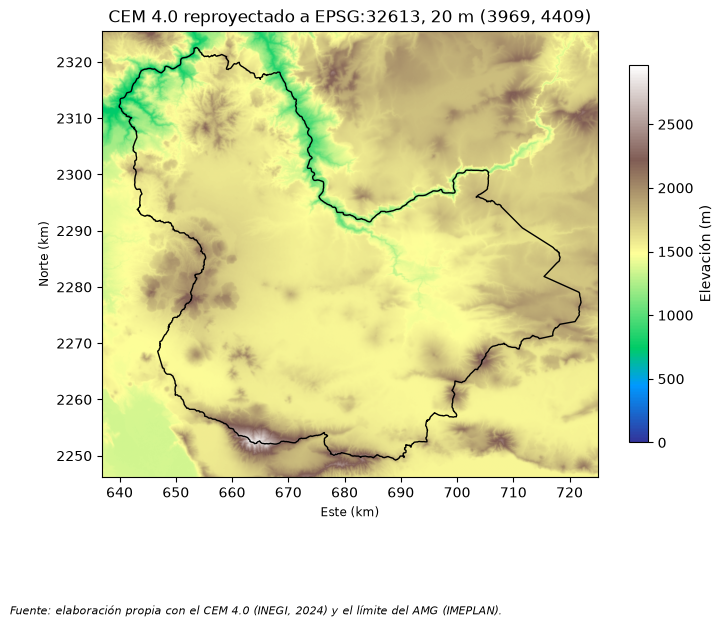

In [2]:
# Código del Paso 2
#Rejilla destino alineada a múltiplos de 20 m
x0 = np.floor((xmin - MARGEN) / RES) * RES
y1 = np.ceil((ymax + MARGEN) / RES) * RES
ancho = int(np.ceil((xmax + MARGEN - x0) / RES))
alto = int(np.ceil((y1 - (ymin - MARGEN)) / RES))
T = from_origin(x0, y1, RES, RES)

imagen = np.zeros((alto, ancho), dtype=np.float64)
reproject(cem, imagen, src_transform=T_cem, src_crs=crs_cem,
          dst_transform=T, dst_crs=CRS, resampling=Resampling.bilinear)

extension = [x0 / 1000, (x0 + ancho * RES) / 1000, (y1 - alto * RES) / 1000, y1 / 1000]   # en km
print("Dimensiones de la imagen reproyectada:", imagen.shape)
print("Tamaño del pixel: %d m x %d m" % (RES, RES))

#Máscara de la ZMG (True dentro del límite)
dentro = ~geometry_mask(limite.geometry, out_shape=imagen.shape, transform=T)
print("Pixeles dentro de la ZMG: %d (%.0f km²)" % (dentro.sum(), dentro.sum() * RES**2 / 1e6))

plt.figure(figsize=(8, 7))
plt.imshow(imagen, cmap="terrain", extent=extension)
plt.colorbar(shrink=0.7, label="Elevación (m)")
#Contorno de la ZMG en km
limite.boundary.affine_transform([1 / 1000, 0, 0, 1 / 1000, 0, 0]).plot(ax=plt.gca(), color="black", linewidth=1)
plt.title("CEM 4.0 reproyectado a EPSG:32613, 20 m " + str(imagen.shape))
plt.xlabel("Este (km)")
plt.ylabel("Norte (km)")
plt.figtext(0.01, -0.02, FUENTE, fontsize=8, style="italic")
plt.savefig(FIG / "fase2a_paso2_dem.png", dpi=200, bbox_inches="tight")
plt.show()

**3.** Definir las funciones de **Convolución** y **Normalización** (las mismas del notebook `01_pipeline_CEM.ipynb`):

$$g(x,y)=\sum_{s}\sum_{t}h(s,t)\,f(x-s,\,y-t)$$

In [3]:
# Código del Paso 3
def convolucion(imagen, filtro):
    #Convolución 2D de una imagen de una banda con un filtro de cualquier tamaño.
    #g(x,y) = sum_s sum_t h(s,t) * f(x-s, y-t)
    kf, kc = filtro.shape
    pf, pc = kf // 2, kc // 2

    #La convolución requiere rotar el filtro 180 grados
    h = np.flipud(np.fliplr(filtro))

    #Relleno de borde: se repite el pixel más cercano
    f_pad = np.pad(imagen, ((pf, pf), (pc, pc)), mode="edge")

    filas, cols = imagen.shape
    g = np.zeros((filas, cols))
    #Cada coeficiente del filtro se multiplica por la ventana desplazada de la imagen
    for s in range(kf):
        for t in range(kc):
            if h[s, t] != 0:
                g += h[s, t] * f_pad[s:s + filas, t:t + cols]
    return g


def normalizacion(imagen_conv):
    #1. Normalización al intervalo [0, 1]
    #2. Escalamiento a 256 valores [0, 255]
    #3. Conversión a valores enteros (uint8)
    minimo, maximo = imagen_conv.min(), imagen_conv.max()
    if maximo == minimo:
        normalizada = np.zeros_like(imagen_conv)
    else:
        normalizada = (imagen_conv - minimo) / (maximo - minimo)
    return np.round(normalizada * 255).astype(np.uint8)

identidad = np.zeros((3, 3))
identidad[1, 1] = 1
print("Convolución con identidad igual a la entrada:", np.allclose(convolucion(imagen, identidad), imagen))

Convolución con identidad igual a la entrada: True


**4.** Aplicar el **Filtro Gaussiano** de 5x5 con σ = 1 pixel para reducir el ruido del radar antes de derivar:

$$G(x,y)=\frac{1}{2\pi\sigma^2}\,e^{-\frac{x^2+y^2}{2\sigma^2}}$$

[[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]


Cambio medio por el suavizado: 0.54 m


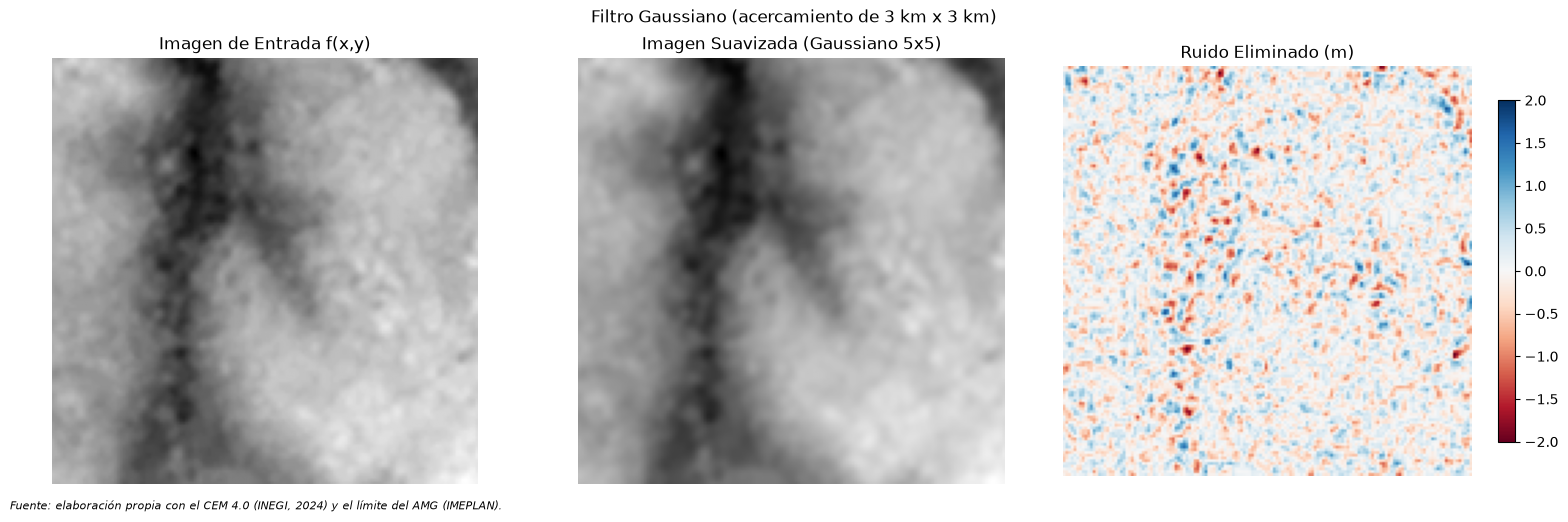

In [4]:
# Código del Paso 4
def filtro_gaussiano(tamano, sigma):
    #Matriz de convolución gaussiana normalizada (sus coeficientes suman 1)
    r = tamano // 2
    y, x = np.mgrid[-r:r + 1, -r:r + 1]
    g = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return g / g.sum()

SIGMA = 1.0
gauss = filtro_gaussiano(5, SIGMA)
print(np.round(gauss, 4))

imagen_suave = convolucion(imagen, gauss)
print("Cambio medio por el suavizado: %.2f m" % np.abs(imagen - imagen_suave).mean())

#Acercamiento de 150 x 150 pixeles (3 km x 3 km) al centro de la imagen
r0, c0 = imagen.shape[0] // 2 - 75, imagen.shape[1] // 2 - 75
v = (slice(r0, r0 + 150), slice(c0, c0 + 150))
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(normalizacion(imagen[v]), cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Imagen de Entrada f(x,y)")
ax[1].imshow(normalizacion(imagen_suave[v]), cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Imagen Suavizada (Gaussiano 5x5)")
im = ax[2].imshow(imagen[v] - imagen_suave[v], cmap="RdBu", vmin=-2, vmax=2)
ax[2].set_title("Ruido Eliminado (m)")
plt.colorbar(im, ax=ax[2], shrink=0.8)
for a in ax:
    a.axis("off")
plt.suptitle("Filtro Gaussiano (acercamiento de 3 km x 3 km)")
plt.tight_layout()
plt.figtext(0.01, -0.02, FUENTE, fontsize=8, style="italic")
plt.savefig(FIG / "fase2a_paso4_gaussiano.png", dpi=200, bbox_inches="tight")
plt.show()

**5.** Aplicar los **Filtros Sobel** en *x* y en *y* para obtener el gradiente y la **pendiente** en grados. Como el pixel ya mide 20 m en ambas direcciones, la respuesta de Sobel se divide entre $8 \cdot 20$ m:

$$S_x=\begin{Bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{Bmatrix}\qquad S_y=\begin{Bmatrix}-1&-2&-1\\0&0&0\\1&2&1\end{Bmatrix}\qquad \theta=\arctan\sqrt{\left(\tfrac{\partial z}{\partial x}\right)^2+\left(\tfrac{\partial z}{\partial y}\right)^2}$$

Pendiente dentro de la ZMG: mediana 4.2°, percentil 95 26.3°


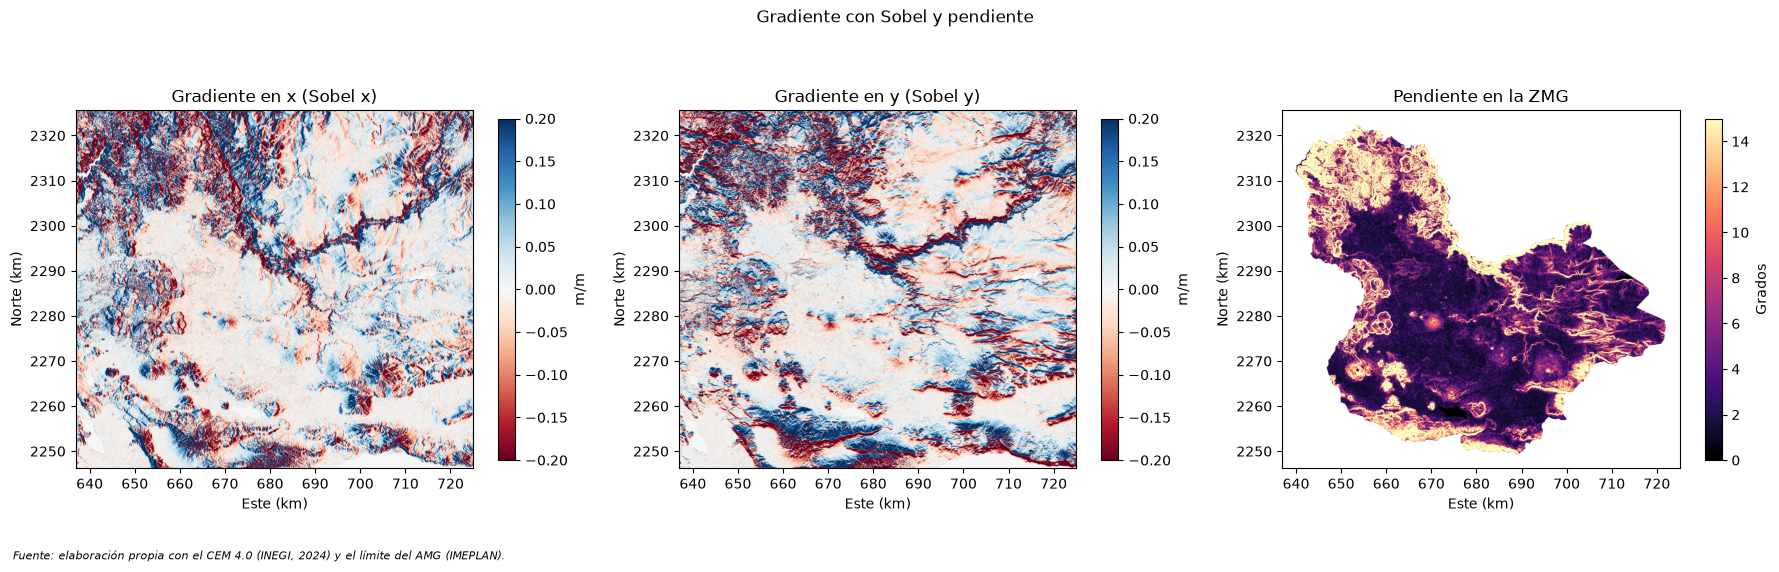

In [5]:
# Código del Paso 5
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=np.float64)
sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]], dtype=np.float64)

#Gradiente en m/m (se cambia el signo porque la convolución rota el filtro)
gx = -convolucion(imagen_suave, sobel_x) / (8 * RES)
gy = -convolucion(imagen_suave, sobel_y) / (8 * RES)
pendiente = np.degrees(np.arctan(np.hypot(gx, gy)))

print("Pendiente dentro de la ZMG: mediana %.1f°, percentil 95 %.1f°"
      % (np.median(pendiente[dentro]), np.percentile(pendiente[dentro], 95)))

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
im = ax[0].imshow(gx, cmap="RdBu", vmin=-0.2, vmax=0.2, extent=extension)
ax[0].set_title("Gradiente en x (Sobel x)")
plt.colorbar(im, ax=ax[0], shrink=0.7, label="m/m")
im = ax[1].imshow(gy, cmap="RdBu", vmin=-0.2, vmax=0.2, extent=extension)
ax[1].set_title("Gradiente en y (Sobel y)")
plt.colorbar(im, ax=ax[1], shrink=0.7, label="m/m")
im = ax[2].imshow(np.where(dentro, pendiente, np.nan), cmap="magma", vmin=0, vmax=15, extent=extension)
ax[2].set_title("Pendiente en la ZMG")
plt.colorbar(im, ax=ax[2], shrink=0.7, label="Grados")
for a in ax:
    a.set_xlabel("Este (km)")
    a.set_ylabel("Norte (km)")
plt.suptitle("Gradiente con Sobel y pendiente")
plt.tight_layout()
plt.figtext(0.01, -0.02, FUENTE, fontsize=8, style="italic")
plt.savefig(FIG / "fase2a_paso5_pendiente.png", dpi=200, bbox_inches="tight")
plt.show()

**6.** Calcular el **Topographic Position Index (TPI)**: la elevación de cada pixel menos el promedio de su entorno de ≈ 1 km. El entorno se obtiene con un **Filtro Promedio** de 51x51 pixeles (51 x 20 m = 1,020 m), aplicado como dos convoluciones 1D (1x51 y 51x1) porque el filtro es separable:

$$TPI(x,y)=z(x,y)-\frac{1}{51^2}\sum_{s}\sum_{t}z(x-s,\,y-t)$$

Un TPI negativo indica que el pixel está **más bajo que su entorno** (hondonada, cauce o zona donde se acumula el agua); uno positivo, que está más alto (loma o cerro). Es la misma "elevación relativa" del notebook `01_pipeline_CEM.ipynb`; allá se usaron 67 pixeles de 15 m (≈ 1 km).

TPI dentro de la ZMG: percentil 5 = -31.7 m, percentil 95 = 36.2 m
Área más baja que su entorno (TPI < 0): 52.6 % de la ZMG


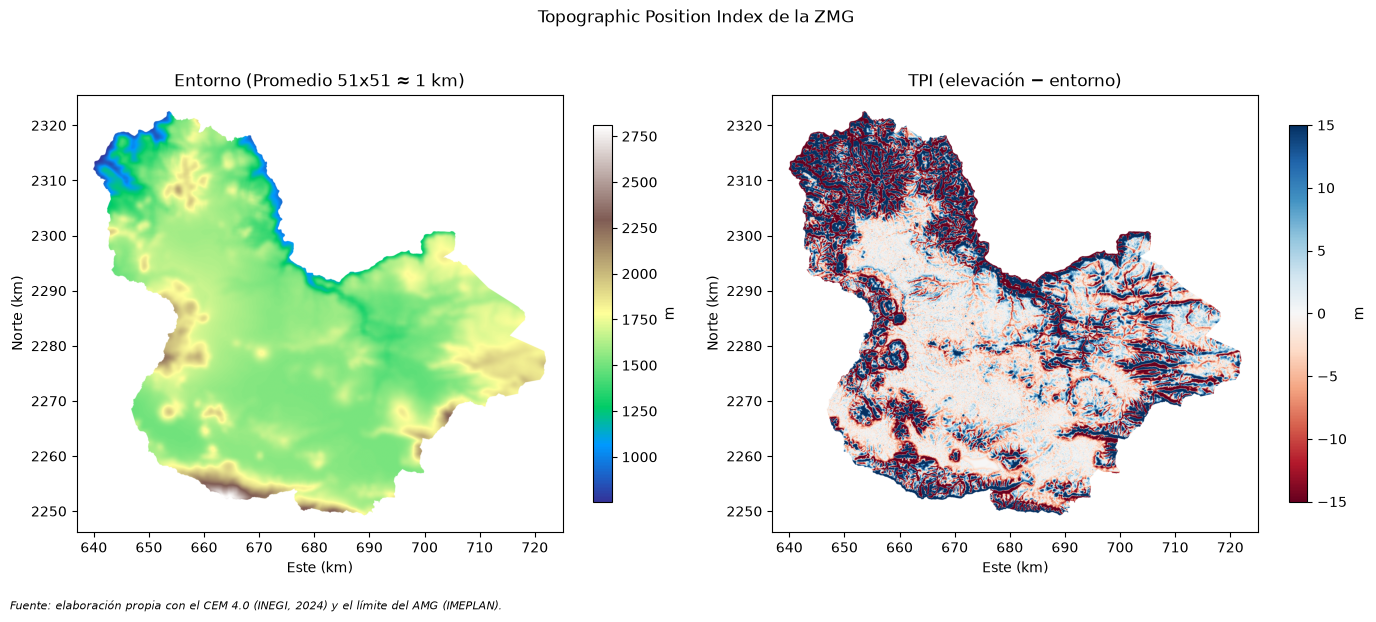

In [6]:
# Código del Paso 6
def filtro_promedio(imagen, n):
    #Filtro promedio n x n aplicado como dos convoluciones 1D (filtro separable)
    fila = np.ones((1, n)) / n
    columna = np.ones((n, 1)) / n
    return convolucion(convolucion(imagen, fila), columna)

VENTANA = 51
entorno = filtro_promedio(imagen, VENTANA)
tpi = imagen - entorno

print("TPI dentro de la ZMG: percentil 5 = %.1f m, percentil 95 = %.1f m" % tuple(np.percentile(tpi[dentro], [5, 95])))
print("Área más baja que su entorno (TPI < 0): %.1f %% de la ZMG" % (100 * (tpi[dentro] < 0).mean()))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
im = ax[0].imshow(np.where(dentro, entorno, np.nan), cmap="terrain", extent=extension)
ax[0].set_title("Entorno (Promedio 51x51 ≈ 1 km)")
plt.colorbar(im, ax=ax[0], shrink=0.7, label="m")
im = ax[1].imshow(np.where(dentro, tpi, np.nan), cmap="RdBu", vmin=-15, vmax=15, extent=extension)
ax[1].set_title("TPI (elevación − entorno)")
plt.colorbar(im, ax=ax[1], shrink=0.7, label="m")
for a in ax:
    a.set_xlabel("Este (km)")
    a.set_ylabel("Norte (km)")
plt.suptitle("Topographic Position Index de la ZMG")
plt.tight_layout()
plt.figtext(0.01, -0.02, FUENTE, fontsize=8, style="italic")
plt.savefig(FIG / "fase2a_paso6_tpi.png", dpi=200, bbox_inches="tight")
plt.show()

**7.** Aplicar la máscara de la ZMG (fuera del límite = sin dato), guardar los tres rásters como GeoTIFF y hacer una **prueba de sentido** con dos colonias conocidas: **Las Conchas** (zona baja e inundable del sur de Guadalajara) debe salir plana y con TPI negativo; **Volcán del Colli** (faldas del cerro del Colli, Zapopan) debe salir con mucha pendiente:

In [7]:
# Código del Paso 7
SIN_DATO = -9999.0

def guardar_raster(arreglo, nombre):
    salida = np.where(dentro, arreglo, SIN_DATO).astype(np.float32)
    perfil = dict(driver="GTiff", height=alto, width=ancho, count=1, dtype="float32",
                  crs=CRS, transform=T, nodata=SIN_DATO, compress="deflate", tiled=True)
    with rasterio.open(RASTERS / nombre, "w", **perfil) as dst:
        dst.write(salida, 1)
    print("Guardado: %-18s %.1f MB" % (nombre, (RASTERS / nombre).stat().st_size / 1e6))

guardar_raster(imagen, "dem_elevation.tif")
guardar_raster(pendiente, "slope_deg.tif")
guardar_raster(tpi, "tpi_local.tif")

#Prueba de sentido: valores en un círculo de 500 m alrededor de dos colonias
import pandas as pd
colonias = pd.read_csv(RAIZ / "datos/colonias_anexo2.csv")
puntos = colonias[colonias.colonia.isin(["Las Conchas", "Volcán del Colli"])]
puntos = gpd.GeoDataFrame(puntos, geometry=gpd.points_from_xy(puntos.lon, puntos.lat), crs="EPSG:4326").to_crs(CRS)
for nombre, p in zip(puntos.colonia, puntos.geometry):
    c, r = ~T * (p.x, p.y)
    c, r = int(c), int(r)
    k = int(500 / RES)
    yy, xx = np.mgrid[-k:k + 1, -k:k + 1]
    disco = (xx**2 + yy**2) * RES**2 <= 500**2
    sl = (slice(r - k, r + k + 1), slice(c - k, c + k + 1))
    print("%-17s pendiente media %.1f° | TPI medio %+.1f m | %% área baja %.0f %%"
          % (nombre, pendiente[sl][disco].mean(), tpi[sl][disco].mean(), 100 * (tpi[sl][disco] < 0).mean()))

Guardado: dem_elevation.tif  24.7 MB


Guardado: slope_deg.tif      29.2 MB


Guardado: tpi_local.tif      30.4 MB


Las Conchas       pendiente media 1.8° | TPI medio -1.0 m | % área baja 73 %
Volcán del Colli  pendiente media 12.0° | TPI medio -2.5 m | % área baja 73 %


#### Limitaciones:
* El CEM 4.0 se generó con radar de 2006–2011: no refleja rellenos o cortes posteriores y en zonas muy construidas puede incluir parte de la altura de los edificios.
* La reproyección de 15 m a 20 m con interpolación bilineal suaviza ligeramente el relieve; los desniveles de una sola calle no se captan.
* En las laderas el TPI puede ser negativo aunque el agua escurra en lugar de acumularse; por eso el TPI se usa junto con la pendiente en el modelo (Fase 4).